## August Lucky Plus push decision

> **CVM:** What was the true effect of the August Plus push? Should it go to the entire base next week?

**Yes, the push increased 30-day Plus starts in the August test.** Treatment had 71 starts among 560 assigned users (12.68%) and the randomized holdout had 9 among 137 (6.57%). That is a **6.11 percentage-point lift**, or **1.93 times** the holdout rate. Pearson p = 0.0443. With nine holdout starts, use the estimate for planning and verify it in the next test.

**Send next week within the tested activity segment.** Keep a randomized holdout and limit the send to users with at least three successful transactions. At extract, 1,514 met that threshold, had no active Plus and had no August assignment. Recheck eligibility and push reachability before sending. If audience size holds, assign 1,211 to push and 303 to holdout. If August rates repeat, expect about 154 treatment starts versus 80 expected among those same users without a push, or **74 incremental starts**. Expanding to the entire base requires evidence from a less-active segment.

**Compare push costs with incremental subscription value.** At EGP 49 per paid month, 74 incremental starts imply about **EGP 3,626 in gross subscription revenue** if each generates one paid month. Request push provider and infrastructure egress costs, delivery logs, paid subscription duration, payment costs and refunds. Compare incremental subscription contribution with incremental campaign cost.

**Measure notification opt-outs and test an in-app banner.** For users who started with notifications enabled, log permission changes and compare the share who switched them off in push versus holdout. In a follow-up with sufficient traffic, randomize push, an in-app banner on app open, and no message. Evaluate starts and opt-outs per assigned user because banner exposure depends on app opens.

**Definitions.** Count one Plus start outcome per assigned user from August 16 through September 14 inclusive. August 15 starts are excluded because subscription dates lack times. The eligibility audit used the first send at 10:00 UTC on August 15 as its common cutoff.


In [1]:
# Task 3.3 | August Lucky Plus campaign
from pathlib import Path

import pandas as pd
from sqlalchemy import create_engine

ROOT = next(
    folder for folder in (Path.cwd(), Path.cwd().parent)
    if (folder / "data" / "cleaned").is_dir()
)
CLEANED = ROOT / "data" / "cleaned"
CAMPAIGN_ID = "plus_push_aug"
LAUNCH_DATE = "2026-08-15"
PRIMARY_WINDOW_DAYS = 30
AS_OF_DATE = "2026-11-05"
MIN_SUCCESSFUL_TRANSACTIONS = 3
TREATMENT_SHARE = 0.80

campaigns = pd.read_csv(CLEANED / "cvm_campaigns.csv")
subscriptions = pd.read_csv(CLEANED / "plus_subscriptions.csv")
users = pd.read_csv(CLEANED / "users.csv", usecols=["user_id", "signup_ts"])
transactions = pd.read_csv(
    CLEANED / "transactions.csv", usecols=["user_id", "txn_ts", "status"]
)
settings = pd.DataFrame([{
    "campaign_id": CAMPAIGN_ID, "launch_date": LAUNCH_DATE,
    "followup_days": PRIMARY_WINDOW_DAYS,
    "as_of_date": AS_OF_DATE,
    "min_transactions": MIN_SUCCESSFUL_TRANSACTIONS,
    "treatment_share": TREATMENT_SHARE,
}])

engine = create_engine("sqlite://")
campaigns.to_sql("cvm_campaigns", engine, index=False)
subscriptions.to_sql("plus_subscriptions", engine, index=False)
users.to_sql("users", engine, index=False)
transactions.to_sql("transactions", engine, index=False)
settings.to_sql("settings", engine, index=False)

%load_ext sql
%sql engine

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [2]:
%%sql
-- Keep one outcome per assigned user and use the same follow-up in both groups.
DROP VIEW IF EXISTS temp.august_group_rates;

CREATE TEMP VIEW august_group_rates AS
WITH user_outcomes AS (
    SELECT c."group" AS campaign_group,
           EXISTS (
               SELECT 1
               FROM plus_subscriptions AS p
               WHERE p.user_id = c.user_id
                 AND p.plus_start_date > s.launch_date
                 AND p.plus_start_date <= DATE(s.launch_date, '+' || s.followup_days || ' days')
           ) AS started_plus
    FROM cvm_campaigns AS c JOIN settings AS s USING (campaign_id)
)
SELECT campaign_group, COUNT(*) AS assigned_users, SUM(started_plus) AS plus_starts,
       AVG(started_plus) AS subscription_rate
FROM user_outcomes
GROUP BY campaign_group;

SELECT r.campaign_group, r.assigned_users, r.plus_starts,
       ROUND(100 * r.subscription_rate, 2) AS subscription_rate_pct,
       ROUND(100 * (r.subscription_rate - h.subscription_rate), 2) AS lift_vs_holdout_pp
FROM august_group_rates AS r
JOIN august_group_rates AS h ON h.campaign_group = 'holdout'
ORDER BY r.campaign_group = 'holdout';

Out[0]: 
+----------------+----------------+-------------+-----------------------+--------------------+
| campaign_group | assigned_users | plus_starts | subscription_rate_pct | lift_vs_holdout_pp |
+----------------+----------------+-------------+-----------------------+--------------------+
|   treatment    |      560       |      71     |         12.68         |        6.11        |
|    holdout     |      137       |      9      |          6.57         |        0.0         |
+----------------+----------------+-------------+-----------------------+--------------------+


Running query in 'sqlite://'

In [3]:
%%sql
-- Size the fresh test as of the extract. Active subscribers are excluded.
WITH eligible_users AS (
    SELECT t.user_id
    FROM transactions AS t CROSS JOIN settings AS s
    WHERE t.status = 'success' AND t.txn_ts < DATE(s.as_of_date, '+1 day')
    GROUP BY t.user_id
    HAVING COUNT(*) >= MAX(s.min_transactions)
),
audience AS (
    SELECT COALESCE(c."group", 'never assigned') AS august_assignment,
           COUNT(*) AS eligible_without_active_plus
    FROM users AS u
    JOIN eligible_users AS e USING (user_id)
    CROSS JOIN settings AS s
    LEFT JOIN cvm_campaigns AS c ON c.user_id = u.user_id AND c.campaign_id = s.campaign_id
    WHERE u.signup_ts < DATE(s.as_of_date, '+1 day')
      AND NOT EXISTS (
          SELECT 1
          FROM plus_subscriptions AS p
          WHERE p.user_id = u.user_id AND p.plus_start_date <= s.as_of_date
            AND (p.plus_end_date IS NULL OR p.plus_end_date > s.as_of_date)
      )
    GROUP BY august_assignment
),
allocation AS (
    SELECT a.*,
           CASE WHEN august_assignment = 'never assigned'
                THEN CAST(ROUND(eligible_without_active_plus * treatment_share) AS INTEGER)
                ELSE 0 END AS proposed_treatment,
           CASE WHEN august_assignment = 'never assigned'
                THEN eligible_without_active_plus ELSE 0 END AS test_size
    FROM audience AS a CROSS JOIN settings
)
SELECT august_assignment, eligible_without_active_plus, proposed_treatment,
       test_size - proposed_treatment AS proposed_holdout,
       CASE WHEN test_size > 0 THEN ROUND(proposed_treatment * t.subscription_rate) END
           AS projected_treatment_starts,
       CASE WHEN test_size > 0 THEN ROUND((test_size - proposed_treatment) * h.subscription_rate) END
           AS projected_holdout_starts,
       CASE WHEN test_size > 0 THEN ROUND(proposed_treatment * h.subscription_rate) END
           AS treatment_starts_without_push,
       CASE WHEN test_size > 0 THEN ROUND(proposed_treatment * (t.subscription_rate - h.subscription_rate)) END
           AS projected_incremental_starts
FROM allocation
JOIN august_group_rates AS t ON t.campaign_group = 'treatment'
JOIN august_group_rates AS h ON h.campaign_group = 'holdout'
ORDER BY CASE august_assignment WHEN 'never assigned' THEN 1 WHEN 'holdout' THEN 2 ELSE 3 END;

Out[0]: 
+-------------------+------------------------------+--------------------+------------------+----------------------------+--------------------------+-------------------------------+------------------------------+
| august_assignment | eligible_without_active_plus | proposed_treatment | proposed_holdout | projected_treatment_starts | projected_holdout_starts | treatment_starts_without_push | projected_incremental_starts |
+-------------------+------------------------------+--------------------+------------------+----------------------------+--------------------------+-------------------------------+------------------------------+
|   never assigned  |             1514             |        1211        |       303        |           154.0            |           20.0           |              80.0             |             74.0             |
|      holdout      |             131              |         0          |        0         |            None            |           None       

Running query in 'sqlite://'

In [4]:
# Pearson chi-square test of campaign assignment vs. starting Plus within 30 days.
from math import erfc, sqrt
from IPython.display import display

observed = pd.read_sql_query(
    '''
    SELECT campaign_group, plus_starts AS subscribed,
           assigned_users - plus_starts AS did_not_subscribe
    FROM august_group_rates
    ''',
    engine,
    index_col="campaign_group",
).loc[["treatment", "holdout"]]

# Under independence, expected count = row total * column total / grand total.
expected = pd.DataFrame(
    observed.sum(axis=1).to_numpy()[:, None] * observed.sum(axis=0).to_numpy()
    / observed.to_numpy().sum(),
    index=observed.index,
    columns=observed.columns,
)
chi_square = (((observed - expected) ** 2) / expected).to_numpy().sum()

# A 2x2 table has one degree of freedom. This is its chi-square upper-tail probability.
p_value = erfc(sqrt(chi_square / 2))

display(observed)
print(f"Pearson chi-square (df=1, no continuity correction): {chi_square:.3f}")
print(f"p-value: {p_value:.4f} | Smallest expected count: {expected.to_numpy().min():.2f}")
print("The p-value is close to 0.05. Interpret it alongside the estimated lift.")

Pearson chi-square (df=1, no continuity correction): 4.043
p-value: 0.0443 | Smallest expected count: 15.72
The p-value is close to 0.05. Interpret it alongside the estimated lift.


,subscribed,did_not_subscribe
campaign_group,,
treatment,71,489
holdout,9,128


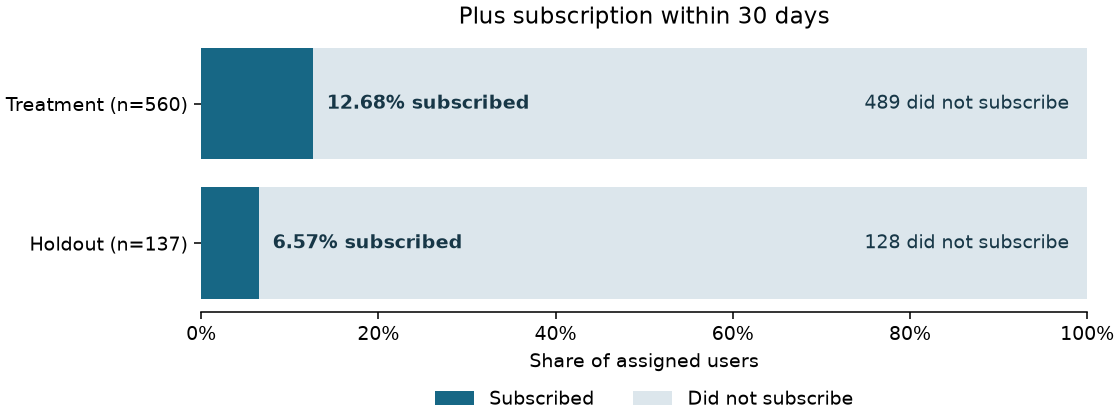

In [5]:
# Compare outcome distributions within each campaign group.
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter

outcome_share = observed.div(observed.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.barh([0, 1], outcome_share["subscribed"], color="#176785", label="Subscribed")
ax.barh([0, 1], outcome_share["did_not_subscribe"],
        left=outcome_share["subscribed"], color="#dce6ec", label="Did not subscribe")

for position, group in enumerate(observed.index):
    subscribed = outcome_share.loc[group, "subscribed"]
    ax.text(subscribed + 0.015, position, f"{subscribed:.2%} subscribed",
            va="center", color="#173747", fontweight="bold")
    no_start = int(observed.loc[group, "did_not_subscribe"])
    ax.text(0.98, position, f"{no_start:,} did not subscribe",
            va="center", ha="right", color="#173747")

ax.set_yticks([0, 1], [f"Treatment (n={observed.loc['treatment'].sum():,})",
                       f"Holdout (n={observed.loc['holdout'].sum():,})"])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="Share of assigned users", title="Plus subscription within 30 days")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)

# Display a PNG so the chart stays visible in the saved notebook.
with BytesIO() as png:
    fig.savefig(png, format="png", dpi=140)
    display(Image(data=png.getvalue()))
plt.close(fig)